# Body fat - JarvisTEC (`body_fat`)

**Team members:** Anthony Jafeth Arias Robleto (2020007243), Randy Espinoza Downing (2021031263), Kenneth Jhoan Araya Arguedas (2024177221)
**Dataset:** [Body Fat Prediction Dataset (Kaggle, fedesoriano/body-fat-prediction-dataset)](https://www.kaggle.com/datasets/fedesoriano/body-fat-prediction-dataset), the body measurements of 252 men published by Johnson (1996) from the data of Penrose et al. (1985).

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

## Configuration

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------- EDIT THESE VALUES -------------------------
# Must match `name` in backend/models/<package>/adapter.py.
MODEL_NAME = "body_fat"
# CSV path relative to training/<name>/ (data/ is git-ignored).
DATA_PATH = "../../data/body_fat/bodyfat.csv"
TARGET_COLUMN = "body_fat"  # % of body weight that is fat
TASK_TYPE = "regression"  # "classification" or "regression"
IS_TIME_SERIES = False  # True for bitcoin, avocado...: chronological split
DATE_COLUMN = None  # date column name when IS_TIME_SERIES is True
# The target is computed from the density (Siri equation): it leaks the
# answer and needs underwater weighing (section 2).
EXCLUDED_COLUMNS = ["density"]
SEED = 42
# ---------------------------------------------------------------------

ARTIFACTS = Path("../../artifacts")
ARTIFACTS.mkdir(exist_ok=True)
np.random.seed(SEED)
assert TASK_TYPE in ("classification", "regression")

## 1. Problem analysis

The goal is to estimate a man's **body fat percentage** (the share of his body weight that is fat) from measurements he can take at home with a scale and a tape measure. An accurate measurement requires underwater weighing or a similar laboratory technique, which is slow and expensive. A quick estimate from simple measurements is useful for following a training or diet plan, where the trend matters more than the exact value.

- **Task type:** regression. The target `body_fat` is a continuous percentage (0.7 to 47.5 in the cleaned data).
- **Success metrics:** **RMSE** (root mean squared error) and **MAE** (mean absolute error), both in percentage points of body fat (called "points" below), so they read directly as "the estimate is off by about X points", and **R2** (the share of the variance explained). The model is always compared with a baseline that predicts the mean body fat of the training set.
- **Design constraint:** the model is used by voice, so every extra input is one more number the user has to measure and dictate. A model with few inputs is preferred when it is about as accurate as one with many.
- **Who uses it and what an error costs (assumption):** we assume the user is an adult man who follows a training or diet plan on his own and asks the assistant for an occasional estimate; nobody else acts on the number. Under that assumption an error is cheap when the estimate is used to follow a trend over time, but it can still mislead: an overestimate may push someone to diet without need, and an underestimate may give false reassurance. These costs were not measured; they are the reason the result is always presented as an estimate with its typical error.
- **Scope:** the estimate is for information only. It is not a medical assessment and must not be used for health decisions, and the data contains only adult men.
- **Support:** Penrose et al. (1985) and Johnson (1996) fit body fat to these same body measurements with multiple regression; the target itself comes from the density-based equation of Siri (1956).

## 2. Data understanding

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (252, 15)


,Density,BodyFat,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,1.0708,12.3,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,1.0853,6.1,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,1.0414,25.3,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,1.0751,10.4,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,1.0340,28.7,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7


In [3]:
# snake_case names with the unit as a suffix: the same fields the API
# receives (backend/models/body_fat/schema.py). Weight and height come in
# pounds and inches; they are converted to kg and cm so that every input
# is metric. The ten circumferences are already in cm.
LB_TO_KG = 0.45359237
IN_TO_CM = 2.54
CIRCUMFERENCES = [
    "neck", "chest", "abdomen", "hip", "thigh", "knee", "ankle", "biceps",
    "forearm", "wrist",
]

df.columns = [c.strip().lower() for c in df.columns]
df = df.rename(columns={"bodyfat": "body_fat"})
df["weight_kg"] = (df.pop("weight") * LB_TO_KG).round(2)
df["height_cm"] = (df.pop("height") * IN_TO_CM).round(1)
df = df.rename(columns={c: f"{c}_cm" for c in CIRCUMFERENCES})
df = df[
    ["density", "body_fat", "age", "weight_kg", "height_cm"]
    + [f"{c}_cm" for c in CIRCUMFERENCES]
]
display(df.head())

,density,body_fat,age,weight_kg,height_cm,neck_cm,chest_cm,abdomen_cm,hip_cm,thigh_cm,knee_cm,ankle_cm,biceps_cm,forearm_cm,wrist_cm
0,1.0708,12.3,23,69.97,172.1,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,1.0853,6.1,22,78.58,183.5,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,1.0414,25.3,22,69.85,168.3,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,1.0751,10.4,26,83.80,183.5,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,1.0340,28.7,24,83.57,181.0,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7


In [4]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(summary)
print("Duplicated rows:", df.duplicated().sum())
display(df.describe(include="all").T)

,dtype,missing,% missing,unique
density,float64,0,0.0,218
body_fat,float64,0,0.0,176
age,int64,0,0.0,51
weight_kg,float64,0,0.0,197
height_cm,float64,0,0.0,48
neck_cm,float64,0,0.0,90
chest_cm,float64,0,0.0,174
abdomen_cm,float64,0,0.0,185
hip_cm,float64,0,0.0,152
thigh_cm,float64,0,0.0,139


Duplicated rows: 0


,count,mean,std,min,25%,50%,75%,max
density,252.0,1.055574,0.019031,0.995,1.0414,1.0549,1.0704,1.1089
body_fat,252.0,19.150794,8.368740,0.000,12.4750,19.2000,25.3000,47.5000
age,252.0,44.884921,12.602040,22.000,35.7500,43.0000,54.0000,81.0000
weight_kg,252.0,81.158452,13.330783,53.750,72.1175,80.0600,89.3600,164.7200
height_cm,252.0,178.176587,9.305915,74.900,173.4000,177.8000,183.5000,197.5000
neck_cm,252.0,37.992063,2.430913,31.100,36.4000,38.0000,39.4250,51.2000
chest_cm,252.0,100.824206,8.430476,79.300,94.3500,99.6500,105.3750,136.2000
abdomen_cm,252.0,92.555952,10.783077,69.400,84.5750,90.9500,99.3250,148.1000
hip_cm,252.0,99.904762,7.164058,85.000,95.5000,99.3000,103.5250,147.7000
thigh_cm,252.0,59.405952,5.249952,47.200,56.0000,59.0000,62.3500,87.3000


Correlation density vs. body_fat: -0.9878
Rows where body_fat equals the Siri value within 0.1 points: 243 of 252


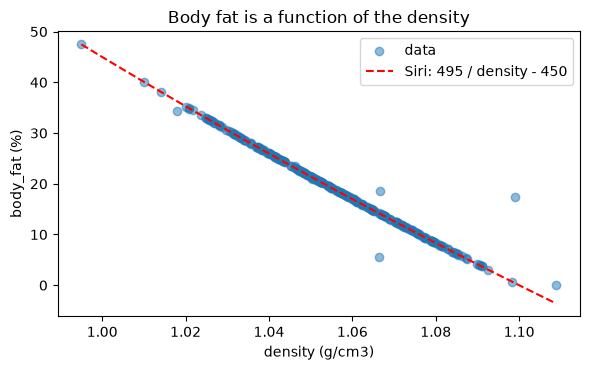

Rows where |body_fat - Siri(density)| > 1 point:


,density,body_fat,siri,gap,age,weight_kg,height_cm,abdomen_cm
47,1.0665,5.6,14.1,-8.5,39,67.36,181.0,79.5
75,1.0666,18.5,14.1,4.4,61,67.25,171.4,81.8
95,1.0991,17.4,0.4,17.0,53,101.83,197.5,99.2
168,1.0180,34.3,36.2,-1.9,35,103.53,176.5,115.9
181,1.1089,0.0,-3.6,3.6,40,53.75,172.7,69.4


Shortest


,body_fat,age,weight_kg,height_cm,abdomen_cm,hip_cm,ankle_cm,bmi
41,32.9,44,92.99,74.9,104.3,115.5,23.7,165.8
73,13.5,55,56.70,162.6,76.0,88.6,19.1,21.4
215,47.5,51,99.34,162.6,122.1,112.8,23.6,37.6


Heaviest


,body_fat,age,weight_kg,height_cm,abdomen_cm,hip_cm,ankle_cm,bmi
38,35.2,46,164.72,183.5,148.1,147.7,29.6,48.9
40,34.5,45,119.18,174.6,126.2,125.6,26.6,39.1
34,32.3,41,112.15,186.7,115.6,116.1,26.3,32.2


Lowest body fat


,body_fat,age,weight_kg,height_cm,abdomen_cm,hip_cm,ankle_cm,bmi
181,0.0,40,53.75,172.7,69.4,85.0,20.2,18.0
171,0.7,35,57.04,166.4,75.0,89.2,22.0,20.6
170,3.0,35,69.06,172.1,81.9,92.8,22.1,23.3


Largest ankle


,body_fat,age,weight_kg,height_cm,abdomen_cm,hip_cm,ankle_cm,bmi
30,11.9,32,82.55,187.3,88.7,99.8,33.9,23.5
85,26.6,67,75.75,171.4,89.7,96.2,33.7,25.8
38,35.2,46,164.72,183.5,148.1,147.7,29.6,48.9


In [5]:
# 1) Leakage check: body fat is not measured, it is computed from the
#    density with the Siri equation: body_fat = 495 / density - 450.
siri = 495 / df["density"] - 450
gap = df["body_fat"] - siri
print(
    "Correlation density vs. body_fat:",
    round(df["density"].corr(df["body_fat"]), 4),
)
print(
    "Rows where body_fat equals the Siri value within 0.1 points:",
    int((gap.abs() <= 0.1).sum()), "of", len(df),
)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.scatter(df["density"], df["body_fat"], alpha=0.5, label="data")
grid = np.linspace(df["density"].min(), df["density"].max(), 100)
ax.plot(grid, 495 / grid - 450, "r--", label="Siri: 495 / density - 450")
ax.set_xlabel("density (g/cm3)")
ax.set_ylabel("body_fat (%)")
ax.set_title("Body fat is a function of the density")
ax.legend()
plt.tight_layout()
plt.show()

# 2) Rows whose body fat does NOT match their own density.
print("Rows where |body_fat - Siri(density)| > 1 point:")
display(
    df.assign(siri=siri.round(1), gap=gap.round(1))
    .loc[gap.abs() > 1, ["density", "body_fat", "siri", "gap", "age",
                         "weight_kg", "height_cm", "abdomen_cm"]]
)

# 3) Extreme body sizes. BMI = kg / m2 is only used to judge plausibility.
bmi = df["weight_kg"] / (df["height_cm"] / 100) ** 2
shown = ["body_fat", "age", "weight_kg", "height_cm", "abdomen_cm",
         "hip_cm", "ankle_cm"]
for label, rows in {
    "Shortest": df["height_cm"].nsmallest(3).index,
    "Heaviest": df["weight_kg"].nlargest(3).index,
    "Lowest body fat": df["body_fat"].nsmallest(3).index,
    "Largest ankle": df["ankle_cm"].nlargest(3).index,
}.items():
    print(label)
    display(df.loc[rows, shown].assign(bmi=bmi.loc[rows].round(1)))

In [6]:
# Decision: remove the rows that cannot be trusted, keep the extreme but
# coherent ones. The original row index is kept to trace every case.
inconsistent_target = gap.abs() > 1  # includes the body fat of 0
impossible_height = df["height_cm"] < 100
removed = df[inconsistent_target | impossible_height]
print("Removed rows (index):", removed.index.tolist())
print("  body fat inconsistent with the density:",
      int(inconsistent_target.sum()))
print("  impossible height:", int(impossible_height.sum()))

df = df[~(inconsistent_target | impossible_height)].copy()
print("Rows kept:", len(df))

# Leakage evidence on the cleaned data: density alone gives the target.
siri_clean = 495 / df["density"] - 450
print(
    "After cleaning, max |body_fat - Siri(density)|:",
    round((df["body_fat"] - siri_clean).abs().max(), 3),
)
print(
    "R2 of the Siri equation as a 'model':",
    round(1 - ((df["body_fat"] - siri_clean) ** 2).sum()
          / ((df["body_fat"] - df["body_fat"].mean()) ** 2).sum(), 5),
)
print("Heaviest man kept (kg):", df["weight_kg"].max())

Removed rows (index): [41, 47, 75, 95, 168, 181]
  body fat inconsistent with the density: 5
  impossible height: 1
Rows kept: 246
After cleaning, max |body_fat - Siri(density)|: 0.459
R2 of the Siri equation as a 'model': 0.99996
Heaviest man kept (kg): 164.72


**Data description.** Body measurements of **252 adult men**. For each man the body density was obtained by underwater weighing and the body fat percentage was computed from it; age, weight, height and ten circumferences were measured with a scale and a tape (Johnson, 1996). The file has 15 columns. Weight and height come in pounds and inches and are converted here to **kg and cm**, so every input is metric. The column names carry the unit as a suffix because they become the API fields.

| Variable | Meaning | Unit | Range in the file |
|---|---|---|---|
| `density` | body density from underwater weighing (**excluded**) | g/cm3 | 0.995 - 1.1089 |
| `body_fat` | body fat percentage (**target**) | % | 0 - 47.5 |
| `age` | age | years | 22 - 81 |
| `weight_kg` | body weight (converted from lb) | kg | 53.75 - 164.72 |
| `height_cm` | height (converted from inches) | cm | 74.9 - 197.5 |
| `neck_cm` | neck circumference | cm | 31.1 - 51.2 |
| `chest_cm` | chest circumference | cm | 79.3 - 136.2 |
| `abdomen_cm` | abdomen circumference | cm | 69.4 - 148.1 |
| `hip_cm` | hip circumference | cm | 85.0 - 147.7 |
| `thigh_cm` | thigh circumference | cm | 47.2 - 87.3 |
| `knee_cm` | knee circumference | cm | 33.0 - 49.1 |
| `ankle_cm` | ankle circumference | cm | 19.1 - 33.9 |
| `biceps_cm` | biceps circumference | cm | 24.8 - 45.0 |
| `forearm_cm` | forearm circumference | cm | 21.0 - 34.9 |
| `wrist_cm` | wrist circumference | cm | 15.8 - 21.4 |

**Data quality:**
- **Missing values and duplicates:** none. The `Pipeline` still imputes with the median so that the backend tolerates a missing field.
- **`density` leaks the target and is excluded.** The body fat was not measured: it was computed from the density with the Siri equation, `body_fat = 495 / density - 450`. The correlation between the two columns is -0.988, and 243 of the 252 rows match the equation within 0.1 points (the plot overlays the data on that curve). On the cleaned data the equation alone reaches an R2 of 0.99996. A model that received `density` would simply relearn the formula and look almost perfect, but it would be useless: a person who can be weighed underwater does not need an estimate.
- **Five rows whose body fat contradicts their own density** (indices 47, 75, 95, 168 and 181, with gaps of 1.9 to 17 points). At least one of the two values in each row must be wrong, and the data does not show which, so the target of these rows cannot be trusted. They include the man with a **body fat of 0** (index 181), whose density gives -3.6 %, an impossible value. The five rows are removed.
- **One impossible height:** index 41 is 74.9 cm tall (29.5 inches) and weighs 93 kg, a body mass index (BMI) of 165.8. This cannot be a real adult. Guessing the intended height would mean inventing data, so the row is removed.
- **One extreme but coherent man is kept:** index 38 weighs 164.7 kg (the next heaviest weighs 119.2 kg), with an abdomen of 148.1 cm and a hip of 147.7 cm. His measurements agree with each other and his body fat matches his density within 1 point, so the row is treated as a real, unusual person and not as an error.
- **Two suspicious ankles** (33.9 and 33.7 cm on men of 82.6 and 75.8 kg, more than the 29.6 cm of the heaviest man). They may be recording errors, but only that column is affected, so the rows are kept.

After cleaning, **246 men** remain. The six removed rows are internally inconsistent: in five the body fat does not match the density, and in one the height is impossible.

**How the rows were removed, and what it means for the evaluation:**
- **The removal happens before the train/test split, and the density rule uses the target.** The rule `|body_fat - Siri(density)| > 1` compares the target with a column the model never receives. It checks the label itself and does not depend on any model, but it was applied to the whole file, including men who would otherwise have landed in the test set.
- **Why 1 point.** The threshold is a judgment call, but the result does not depend on its exact value, because the rows separate into two groups with nothing in between. 243 of the 252 rows match the equation within 0.1 points, and among the 246 rows kept the largest gap is 0.459 points; the five flagged rows have gaps of 1.9, 3.6, 4.4, 8.5 and 17 points. Any threshold from about 0.5 to about 1.9 points therefore leaves the same 246 rows (index 41 is removed by the height rule in any case).
- **Limitation of the evaluation.** Because the six rows were dropped before the split, the test set of section 5 contains only men whose body fat agrees with their density and whose height is possible. The test metrics describe the model on such clean rows; they do not show how it would score on the file as published, which this notebook does not measure. A stricter design would split first, apply the rules to the training part only and report separately the test rows that fail them.

## 3. Data exploration

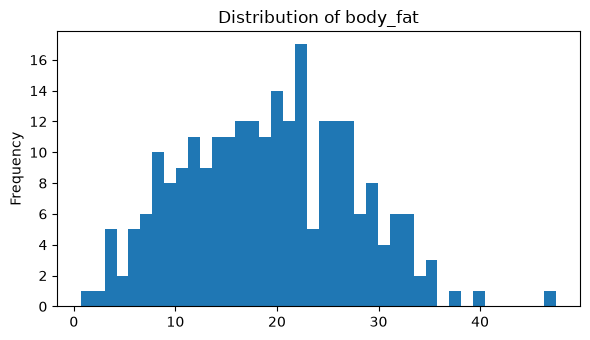

In [7]:
target = TARGET_COLUMN
fig, ax = plt.subplots(figsize=(6, 3.5))
if TASK_TYPE == "classification":
    df[target].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(f"Class distribution: {target}")
    shares = (df[target].value_counts(normalize=True) * 100).round(2)
    display(shares.rename("% of each class"))
else:
    df[target].plot(kind="hist", bins=40, ax=ax)
    ax.set_title(f"Distribution of {target}")
plt.tight_layout()
plt.show()

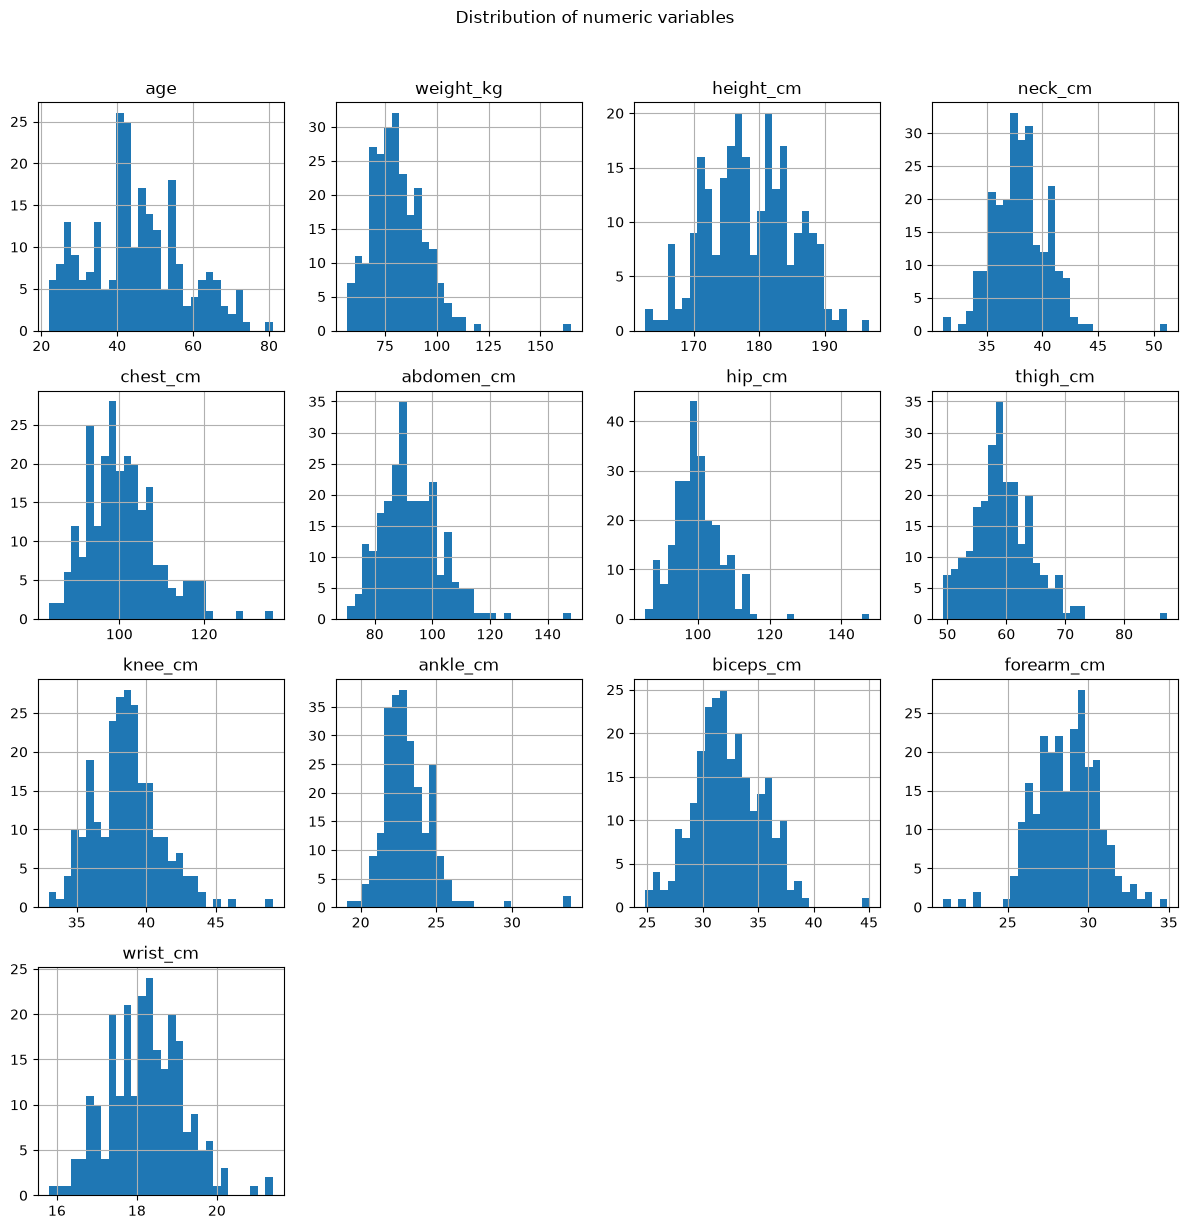

In [8]:
numeric_columns = [
    c for c in df.select_dtypes("number").columns
    if c not in EXCLUDED_COLUMNS + [target]
]
rows = (len(numeric_columns) + 3) // 4
df[numeric_columns].hist(bins=30, figsize=(12, 3 * rows), layout=(-1, 4))
plt.suptitle("Distribution of numeric variables", y=1.02)
plt.tight_layout()
plt.show()

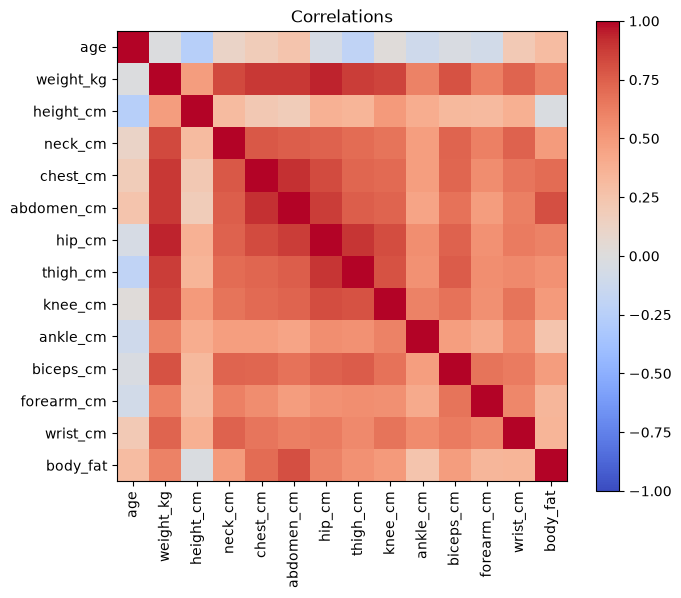

abdomen_cm    0.807261
chest_cm      0.695389
hip_cm        0.608531
weight_kg     0.601566
thigh_cm      0.532563
knee_cm       0.495326
neck_cm       0.484968
biceps_cm     0.479351
wrist_cm      0.347407
forearm_cm    0.342087
age           0.302227
ankle_cm      0.248698
height_cm    -0.025805
Name: correlation with the target, dtype: float64

In [9]:
if len(numeric_columns) > 1:
    corr = df[numeric_columns + [target]].select_dtypes("number").corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)))
    ax.set_yticklabels(corr.columns)
    plt.colorbar(image)
    ax.set_title("Correlations")
    plt.tight_layout()
    plt.show()
    if pd.api.types.is_numeric_dtype(df[target]):
        display(
            corr[target].drop(target)
            .sort_values(key=abs, ascending=False)
            .rename("correlation with the target")
        )

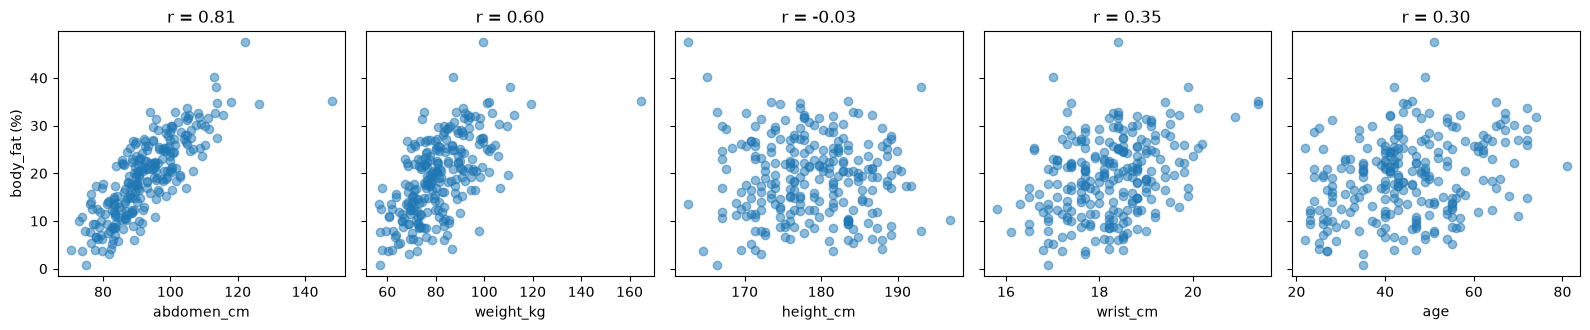

Target:


count    246.00
mean      19.18
std        8.23
min        0.70
25%       12.50
50%       19.25
75%       25.28
max       47.50
Name: body_fat, dtype: float64

Skewness of body_fat: 0.17
Most correlated pairs of inputs:


weight_kg   hip_cm        0.942
chest_cm    abdomen_cm    0.914
hip_cm      thigh_cm      0.893
weight_kg   chest_cm      0.889
            abdomen_cm    0.884
abdomen_cm  hip_cm        0.870
weight_kg   thigh_cm      0.869
            knee_cm       0.850
Name: correlation, dtype: float64

Pairs with |correlation| > 0.8: 11 of 78


forearm_cm    5
wrist_cm      4
abdomen_cm    3
neck_cm       3
chest_cm      3
knee_cm       3
thigh_cm      3
ankle_cm      3
hip_cm        3
weight_kg     2
biceps_cm     1
height_cm     0
age           0
Name: IQR outliers, dtype: int64

BMI of the sample:


count    246.0
mean      25.4
std        3.6
min       19.0
25%       23.1
50%       25.1
75%       27.3
max       48.9
dtype: float64

In [10]:
# Body fat against the measurements a person can take at home.
shown = ["abdomen_cm", "weight_kg", "height_cm", "wrist_cm", "age"]
fig, axes = plt.subplots(1, len(shown), figsize=(16, 3.4), sharey=True)
for ax, column in zip(axes, shown):
    ax.scatter(df[column], df[target], alpha=0.5)
    ax.set_xlabel(column)
    ax.set_title(f"r = {df[column].corr(df[target]):.2f}")
axes[0].set_ylabel("body_fat (%)")
plt.tight_layout()
plt.show()

print("Target:")
display(df[target].describe().round(2))
print("Skewness of body_fat:", round(df[target].skew(), 2))

# Redundancy between inputs: the most correlated pairs.
feature_corr = df[numeric_columns].corr()
pairs = (
    feature_corr.where(np.triu(np.ones(feature_corr.shape, bool), k=1))
    .stack()
    .dropna()
    .sort_values(key=abs, ascending=False)
)
print("Most correlated pairs of inputs:")
display(pairs.head(8).round(3).rename("correlation"))
print(
    "Pairs with |correlation| > 0.8:", int((pairs.abs() > 0.8).sum()),
    "of", len(pairs),
)

# Outliers by the 1.5 x IQR rule.
q1, q3 = df[numeric_columns].quantile(0.25), df[numeric_columns].quantile(0.75)
iqr = q3 - q1
outliers = (
    (df[numeric_columns] < q1 - 1.5 * iqr)
    | (df[numeric_columns] > q3 + 1.5 * iqr)
).sum()
display(outliers.sort_values(ascending=False).rename("IQR outliers"))
bmi = df["weight_kg"] / (df["height_cm"] / 100) ** 2
print("BMI of the sample:")
display(bmi.describe().round(1))

**Exploration findings:**

- **Target:** roughly symmetric (skewness 0.17), with a mean of 19.2 % and a standard deviation of 8.2 points, ranging from 0.7 to 47.5 %. No transformation of the target is needed.
- **The abdomen is the key measurement:** `abdomen_cm` has a correlation of **0.81** with body fat, well above the chest (0.70), the hip (0.61) and the weight (0.60). Such a strong linear correlation favors a linear model.
- **Height says almost nothing by itself** (correlation -0.03), and age and wrist are only weakly related to body fat (0.30 and 0.35).
- **The inputs are highly redundant:** 11 of the 78 pairs of inputs have a correlation above 0.8, for example weight with hip (0.94), chest with abdomen (0.91) and weight with abdomen (0.88). Most circumferences largely measure how big the man is. With 13 correlated inputs and fewer than 250 rows, an unregularized model would have unstable coefficients; this motivates regularized linear models (Ridge, Lasso) and a search for a smaller set of inputs.
- **Outliers:** by the 1.5 x IQR (interquartile range) rule, no variable has more than 5 outlying values (forearm 5, wrist 4, the rest 3 or fewer). They are kept, for the reasons given in section 2.
- **Who is in the sample:** adult men aged 22 to 81 with a mean BMI of 25.4 (median 25.1). Three quarters of them have a BMI below 27.3. There are no women and no children, which limits who the model can be used for.

**Preprocessing decisions:** convert weight and height to metric units; remove the six unreliable rows; exclude `density`; impute with the median and standardize every input inside the `Pipeline` (regularized linear models need comparable scales). There are no categorical variables, so no encoding is needed.

## 4. Model

A baseline is compared with several models using cross-validation, and the best one is chosen. All preprocessing lives inside a `Pipeline`, so the backend receives raw data and the preprocessing is fitted only on the training part of each fold (no information leakage).

The data is split once into training (80 %) and test (20 %). Everything in this section (model comparison, choice of inputs and hyperparameter tuning) uses **only the training set**, with 5-fold cross-validation repeated 5 times because the dataset is small. The one step that happened before the split is the removal of the six unreliable rows (section 2), which is discussed there as a limitation.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    KFold,
    RepeatedKFold,
    StratifiedKFold,
    TimeSeriesSplit,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Duplicates removed before splitting, so no row is in both sets.
data = df.drop_duplicates().copy()
if IS_TIME_SERIES and DATE_COLUMN:
    data[DATE_COLUMN] = pd.to_datetime(data[DATE_COLUMN])
    data = data.sort_values(DATE_COLUMN).reset_index(drop=True)

dropped = [TARGET_COLUMN] + EXCLUDED_COLUMNS
dropped += [DATE_COLUMN] if DATE_COLUMN else []
X = data.drop(columns=dropped)
y = data[TARGET_COLUMN]
numeric_features = X.select_dtypes("number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

if IS_TIME_SERIES:
    cut = int(len(X) * 0.8)
    X_train, X_test = X.iloc[:cut], X.iloc[cut:]
    y_train, y_test = y.iloc[:cut], y.iloc[cut:]
    cv = TimeSeriesSplit(n_splits=5)
else:
    stratify = (
        y if TASK_TYPE == "classification" and y.value_counts().min() >= 2
        else None
    )
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=stratify
    )
    cv = (
        StratifiedKFold(5, shuffle=True, random_state=SEED)
        if stratify is not None
        # Small dataset: 5 folds repeated 5 times (25 fits) give a
        # steadier estimate than a single 5-fold pass.
        else RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)
    )

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Train: (196, 13)  Test: (50, 13)
Numeric: ['age', 'weight_kg', 'height_cm', 'neck_cm', 'chest_cm', 'abdomen_cm', 'hip_cm', 'thigh_cm', 'knee_cm', 'ankle_cm', 'biceps_cm', 'forearm_cm', 'wrist_cm']
Categorical: []


In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import cross_validate

ALL_FEATURES = numeric_features
candidates = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=SEED, n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
}
# Negative RMSE in percentage points of body fat: higher is better.
scoring = "neg_root_mean_squared_error"
score_column = f"{scoring} (mean)"


def make_preprocessor(features):
    # Median imputation + scaling, fitted inside each training fold.
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), features),
    ])


def compare(features, models):
    """Cross-validate every model on the given input columns."""
    rows = []
    for name, estimator in models.items():
        pipeline = Pipeline([
            ("prep", make_preprocessor(features)), ("model", estimator),
        ])
        scores = cross_validate(
            pipeline, X_train[features], y_train, cv=cv, n_jobs=1,
            scoring=(scoring, "neg_mean_absolute_error", "r2"),
            error_score="raise",
        )
        rmse = scores[f"test_{scoring}"]
        rows.append({
            "model": name,
            score_column: rmse.mean(),
            "std": rmse.std(),
            "mae (mean)": -scores["test_neg_mean_absolute_error"].mean(),
            "r2 (mean)": scores["test_r2"].mean(),
        })
    return (
        pd.DataFrame(rows)
        .sort_values(score_column, ascending=False)
        .reset_index(drop=True)
    )


# Step 1: every candidate with the 13 measurements.
comparison_all = compare(ALL_FEATURES, candidates)
display(comparison_all.round(4))

,model,neg_root_mean_squared_error (mean),std,mae (mean),r2 (mean)
0,Lasso,-4.5306,0.3202,3.7606,0.6891
1,Ridge,-4.5455,0.3384,3.7691,0.6853
2,Gradient Boosting,-4.8149,0.3868,4.0038,0.6540
3,Random Forest,-4.8488,0.4364,4.0736,0.6504
4,Baseline,-8.3987,0.8472,6.9250,-0.0299


,added,cv_rmse,std
inputs,,,
1,abdomen_cm,4.9072,0.3327
2,weight_kg,4.5485,0.3339
3,wrist_cm,4.4702,0.3382
4,biceps_cm,4.4536,0.3310
5,forearm_cm,4.4551,0.3360
6,age,4.4548,0.3399
7,height_cm,4.4618,0.3498
8,chest_cm,4.4620,0.3580
9,hip_cm,4.4703,0.3541


Best CV RMSE: 4.4536 with 4 inputs
Chosen: 2 inputs -> ['abdomen_cm', 'weight_kg'] (CV RMSE 4.5485)


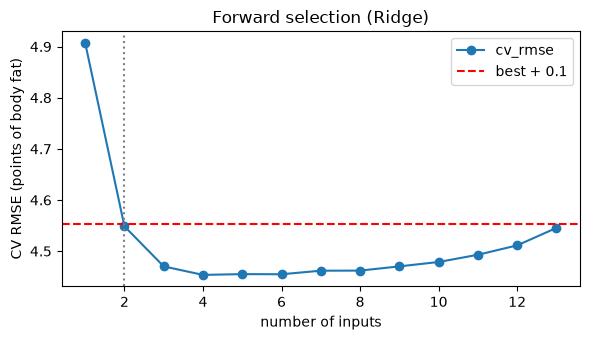

In [13]:
# Step 2: how many measurements are really needed? Greedy forward
# selection with Ridge: at each step, add the input that lowers the
# cross-validated RMSE the most. Train set only.
selected, steps = [], []
remaining = list(ALL_FEATURES)
while remaining:
    trials = {}
    for feature in remaining:
        pipeline = Pipeline([
            ("prep", make_preprocessor(selected + [feature])),
            ("model", Ridge(alpha=1.0)),
        ])
        trials[feature] = cross_val_score(
            pipeline, X_train[selected + [feature]], y_train, cv=cv,
            scoring=scoring, n_jobs=1, error_score="raise",
        )
    best_feature = max(trials, key=lambda f: trials[f].mean())
    selected.append(best_feature)
    remaining.remove(best_feature)
    steps.append({
        "inputs": len(selected),
        "added": best_feature,
        "cv_rmse": -trials[best_feature].mean(),
        "std": trials[best_feature].std(),
    })
forward = pd.DataFrame(steps).set_index("inputs")
display(forward.round(4))

# Rule fixed before looking at the test set: the smallest number of inputs
# whose CV RMSE is within TOLERANCE points of the best one.
TOLERANCE = 0.1
best_rmse = forward["cv_rmse"].min()
N_INPUTS = int(forward.index[forward["cv_rmse"] <= best_rmse + TOLERANCE][0])
FEATURES = forward["added"].iloc[:N_INPUTS].tolist()
print(f"Best CV RMSE: {best_rmse:.4f} with",
      int(forward["cv_rmse"].idxmin()), "inputs")
print(f"Chosen: {N_INPUTS} inputs -> {FEATURES}",
      f"(CV RMSE {forward.loc[N_INPUTS, 'cv_rmse']:.4f})")

ax = forward["cv_rmse"].plot(marker="o", figsize=(6, 3.5))
ax.axhline(best_rmse + TOLERANCE, color="r", linestyle="--",
           label=f"best + {TOLERANCE}")
ax.axvline(N_INPUTS, color="gray", linestyle=":")
ax.set_xlabel("number of inputs")
ax.set_ylabel("CV RMSE (points of body fat)")
ax.set_title("Forward selection (Ridge)")
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
# Step 3: the same candidates, now trained only on the chosen inputs.
# From here on X holds exactly the fields the API will receive.
X, X_train, X_test = X[FEATURES], X_train[FEATURES], X_test[FEATURES]
numeric_features, categorical_features = FEATURES, []
preprocessor = make_preprocessor(FEATURES)

comparison = compare(FEATURES, candidates)
display(comparison.round(4))

,model,neg_root_mean_squared_error (mean),std,mae (mean),r2 (mean)
0,Ridge,-4.5485,0.3339,3.7493,0.6876
1,Lasso,-4.5684,0.3231,3.7678,0.6857
2,Random Forest,-5.0931,0.4563,4.2150,0.6124
3,Gradient Boosting,-5.1803,0.4979,4.2422,0.5989
4,Baseline,-8.3987,0.8472,6.9250,-0.0299


In [15]:
BEST = comparison.loc[~comparison["model"].eq("Baseline"), "model"].iloc[0]
print("Chosen model:", BEST)
final_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates[BEST]),
])
final_pipeline.fit(X_train, y_train)

Chosen model: Ridge


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['abdomen_cm','weight_kg']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,e

In [16]:
# Hyperparameter tuning of the chosen model: cross-validation on TRAIN only.
from sklearn.model_selection import RandomizedSearchCV

SEARCH_SPACES = {
    "Ridge": {"model__alpha": np.logspace(-2, 3, 16).round(4).tolist()},
    "Lasso": {"model__alpha": np.logspace(-3, 1, 16).round(4).tolist()},
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 4, 8],
        "model__min_samples_leaf": [1, 3, 5, 10],
        "model__max_features": [0.5, 1.0],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200, 400],
        "model__learning_rate": [0.01, 0.03, 0.1],
        "model__max_depth": [1, 2, 3],
        "model__subsample": [0.8, 1.0],
    },
}
space = SEARCH_SPACES[BEST]

HYPERPARAMETERS = {}
search = RandomizedSearchCV(
    final_pipeline,
    space,
    n_iter=min(20, int(np.prod([len(v) for v in space.values()]))),
    cv=cv,
    scoring=scoring,
    random_state=SEED,
    n_jobs=1,
    error_score="raise",
)
search.fit(X_train, y_train)
untuned = comparison.loc[comparison["model"].eq(BEST), score_column].iloc[0]
print(
    f"{scoring} CV untuned: {untuned:.4f} | tuned: {search.best_score_:.4f}"
)
print("Best parameters found:", search.best_params_)
if search.best_score_ > untuned:
    final_pipeline = search.best_estimator_
    HYPERPARAMETERS = {
        key.removeprefix("model__"): value
        for key, value in search.best_params_.items()
    }
print("Hyperparameters used:", HYPERPARAMETERS or "defaults")

results = pd.DataFrame(search.cv_results_)
curve = (
    results.assign(cv_rmse=-results["mean_test_score"])
    .sort_values("cv_rmse")[["params", "cv_rmse", "std_test_score"]]
)
display(curve.head(5).round(4))
display(curve.tail(3).round(4))

neg_root_mean_squared_error CV untuned: -4.5485 | tuned: -4.5451
Best parameters found: {'model__alpha': 0.01}
Hyperparameters used: {'alpha': 0.01}


,params,cv_rmse,std_test_score
0,{'model__alpha': 0.01},4.5451,0.3455
1,{'model__alpha': 0.0215},4.5451,0.3454
2,{'model__alpha': 0.0464},4.5451,0.3450
3,{'model__alpha': 0.1},4.5451,0.3443
4,{'model__alpha': 0.2154},4.5453,0.3428


,params,cv_rmse,std_test_score
13,{'model__alpha': 215.4435},6.1272,0.6345
14,{'model__alpha': 464.1589},6.7739,0.7039
15,{'model__alpha': 1000.0},7.4024,0.7619


**Model choice.** The work was done in three steps, all with repeated 5-fold cross-validation (25 fits per estimate) on the training set (196 men), scored by cross-validated (CV) RMSE in points of body fat.

**Step 1 - all 13 measurements.** Five candidates were compared: a **baseline** that always predicts the mean; two regularized linear models, **Ridge** (Hoerl & Kennard, 1970) and **Lasso** (Tibshirani, 1996); and two tree ensembles, **Random Forest** (Breiman, 2001) and **Gradient Boosting** (Friedman, 2001).

| Model (13 inputs) | CV RMSE | CV R2 |
|---|---|---|
| Lasso | **4.53** | 0.689 |
| Ridge | 4.55 | 0.685 |
| Gradient Boosting | 4.81 | 0.654 |
| Random Forest | 4.85 | 0.650 |
| Baseline | 8.40 | -0.030 |

The linear models beat the tree ensembles. This agrees with the exploration, which found a strong linear correlation with the abdomen; with fewer than 200 training rows, the flexibility of the ensembles did not pay off. The difference between the two linear models (about 0.015) is far smaller than the variation across folds (standard deviation about 0.33).

**Step 2 - how many inputs are needed.** A greedy forward selection with Ridge added, one at a time, the input that lowered the CV RMSE the most:

| Inputs | Added | CV RMSE |
|---|---|---|
| 1 | `abdomen_cm` | 4.91 |
| 2 | `weight_kg` | 4.55 |
| 3 | `wrist_cm` | 4.47 |
| 4 | `biceps_cm` | **4.45** |
| 13 | (all) | 4.55 |

The abdomen alone cuts the baseline error from 8.40 to 4.91, and adding the weight brings it to 4.55. After that the curve is nearly flat: the best point (4 inputs, 4.45) is less than 0.1 better, and adding the remaining measurements brings the error back up to 4.55 with all 13. The rule fixed in the code is to take the smallest set within 0.1 points of the best, which gives **two inputs: `abdomen_cm` and `weight_kg`**. For a voice assistant this is a large practical gain (two numbers to dictate instead of thirteen), and the two-input model has the same CV RMSE as the 13-input one (4.55). Because the selection used the same folds that score it, the RMSE of the selected sets is slightly optimistic; the test set of section 5 was not used in the selection.

**The 0.1 tolerance is a judgment call, and the rule is met narrowly.** The limit is the best CV RMSE plus the tolerance, 4.4536 + 0.1 = 4.5536, and the two-input set scores 4.5485: it is inside the limit by about 0.005 points. A slightly smaller tolerance (0.09, for example) would have selected three inputs instead, adding `wrist_cm` (4.4702). No criterion from the data fixes the value of the tolerance: it expresses how much accuracy we accept to give up in exchange for fewer numbers to dictate. What supports the choice is that the difference at stake (4.5485 with two inputs against 4.4536 with four) is small next to the variation across folds (standard deviation about 0.33), so the cross-validation cannot tell these sets apart with confidence.

**Step 3 - the candidates again, with the two inputs.**

| Model (2 inputs) | CV RMSE | CV MAE | CV R2 |
|---|---|---|---|
| Ridge | **4.55** | 3.75 | 0.688 |
| Lasso | 4.57 | 3.77 | 0.686 |
| Random Forest | 5.09 | 4.22 | 0.612 |
| Gradient Boosting | 5.18 | 4.24 | 0.599 |
| Baseline | 8.40 | 6.93 | -0.030 |

**Ridge** is chosen. The tree ensembles are clearly worse here (5.09 and 5.18), and a linear model with two inputs can be written as a single equation, which makes it easy to explain and to audit.

**Hyperparameter tuning: which candidates were tuned.** Only the chosen model, **Ridge**, was tuned. Lasso, Random Forest and Gradient Boosting were compared in steps 1 and 3 with the fixed settings written in the code (`alpha = 0.1` for Lasso, 300 trees for Random Forest, the library defaults for Gradient Boosting) and were **not** tuned, and the forward selection of step 2 used Ridge with its default `alpha = 1`. The comparison between candidates is therefore a comparison of untuned models; a tuned tree ensemble could score differently from what the tables show. The hyperparameter tuned for Ridge is the regularization strength `alpha`. A search over 16 values between 0.01 and 1000 (logarithmic grid), with the same cross-validation on the training set only, gave:
- **Best value:** `alpha = 0.01`, the smallest of the grid, with a CV RMSE of 4.5451 against 4.5485 for the default `alpha = 1`.
- **Reading:** the curve is flat from 0.01 to about 0.2 (4.5451 to 4.5453) and only degrades with strong regularization (7.40 at `alpha = 1000`). With two inputs and 196 rows there is almost nothing to regularize: the tuned model is practically an ordinary least squares regression. The value found by the search is used because the rule in the code is to adopt it whenever it improves the cross-validated score, but in practice tuning made no real difference for this model.

## 5. Evaluation

The chosen model is evaluated on the held-out test set, which was not used for training, model selection or tuning. Any other model or configuration scored on the test set below is shown for reference only and did not influence a choice.

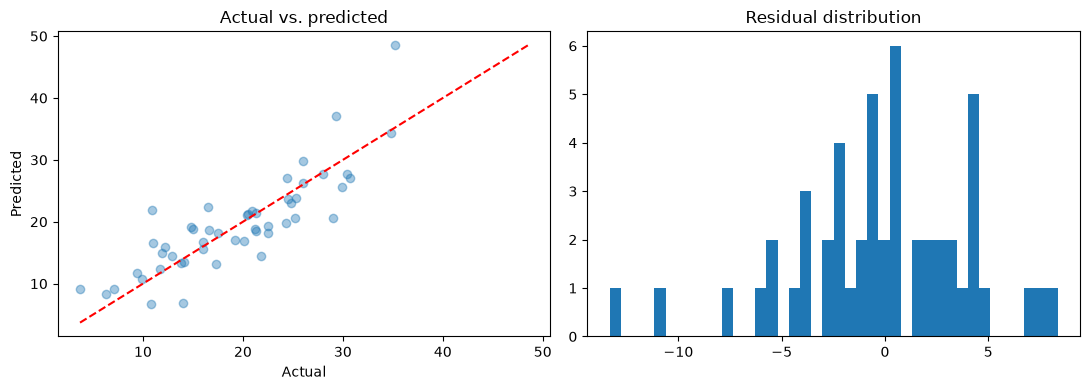

rmse    4.2676
mae     3.2275
r2      0.6716
Name: test metrics, dtype: float64

Baseline RMSE on test: 7.4509


In [17]:
from sklearn import metrics

predictions = final_pipeline.predict(X_test)

if TASK_TYPE == "classification":
    test_metrics = {
        "accuracy": metrics.accuracy_score(y_test, predictions),
        "f1_macro": metrics.f1_score(y_test, predictions, average="macro"),
        "precision_macro": metrics.precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "recall_macro": metrics.recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
    }
    print(metrics.classification_report(
        y_test, predictions, zero_division=0
    ))
    fig, ax = plt.subplots(figsize=(5, 4.5))
    metrics.ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title("Confusion matrix")
    plt.tight_layout()
    plt.show()
else:
    test_metrics = {
        "rmse": metrics.mean_squared_error(y_test, predictions) ** 0.5,
        "mae": metrics.mean_absolute_error(y_test, predictions),
        "r2": metrics.r2_score(y_test, predictions),
    }
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].scatter(y_test, predictions, alpha=0.4)
    limits = [
        min(y_test.min(), predictions.min()),
        max(y_test.max(), predictions.max()),
    ]
    ax[0].plot(limits, limits, "r--")
    ax[0].set_xlabel("Actual")
    ax[0].set_ylabel("Predicted")
    ax[0].set_title("Actual vs. predicted")
    ax[1].hist(y_test - predictions, bins=40)
    ax[1].set_title("Residual distribution")
    plt.tight_layout()
    plt.show()

test_metrics = {k: round(float(v), 4) for k, v in test_metrics.items()}
display(pd.Series(test_metrics, name="test metrics"))

# Baseline on the same test set, to check the model really adds value.
baseline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates["Baseline"]),
]).fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
if TASK_TYPE == "classification":
    baseline_score = metrics.f1_score(
        y_test, baseline_predictions, average="macro"
    )
    print("Baseline f1_macro on test:", round(baseline_score, 4))
else:
    baseline_score = (
        metrics.mean_squared_error(y_test, baseline_predictions) ** 0.5
    )
    print("Baseline RMSE on test:", round(baseline_score, 4))

weight_kg     -3.9101
abdomen_cm    10.2825
Name: Coefficients (points of body fat per standard deviation), dtype: float64

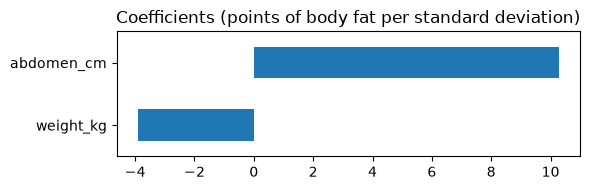

body_fat = -48.109  +1.0055 * abdomen_cm -0.3173 * weight_kg


In [18]:
# What the model learned: coefficients (linear model) or importances.
estimator = final_pipeline.named_steps["model"]
feature_names = [
    name.removeprefix("num__")
    for name in final_pipeline.named_steps["prep"].get_feature_names_out()
]
if hasattr(estimator, "feature_importances_"):
    weights, title = estimator.feature_importances_, "Feature importance"
else:
    weights = estimator.coef_
    title = "Coefficients (points of body fat per standard deviation)"
importance = pd.Series(weights, index=feature_names).sort_values(key=abs)
display(importance.round(4).rename(title))
importance.plot(kind="barh", figsize=(6, 1 + 0.5 * len(importance)),
                title=title)
plt.tight_layout()
plt.show()

if hasattr(estimator, "coef_"):
    # The same linear model written in the original units.
    scaler = final_pipeline.named_steps["prep"].named_transformers_["num"]
    scale = scaler.named_steps["scale"]
    slopes = pd.Series(estimator.coef_ / scale.scale_, index=feature_names)
    intercept = estimator.intercept_ - (slopes.values * scale.mean_).sum()
    print("body_fat =", round(float(intercept), 3), "".join(
        f" {value:+.4f} * {name}" for name, value in slopes.items()
    ))

In [19]:
# Error analysis on the test set.
errors = X_test.assign(
    actual=y_test,
    predicted=predictions.round(1),
    error=(predictions - y_test).round(1),
)
errors["abs_error"] = errors["error"].abs()
errors["segment"] = pd.cut(
    errors["actual"], [0, 10, 20, 30, np.inf],
    labels=["< 10 %", "10-20 %", "20-30 %", "> 30 %"],
)
display(
    errors.groupby("segment", observed=True)
    .agg(n=("actual", "size"), mae=("abs_error", "mean"),
         mean_error=("error", "mean"))
    .round(2)
)
print("Share of test men within 3 points:",
      round((errors["abs_error"] <= 3).mean(), 3))
print("Share of test men within 5 points:",
      round((errors["abs_error"] <= 5).mean(), 3))
print("Largest errors:")
display(errors.sort_values("abs_error", ascending=False).head(5))
print("Mean error (predicted - actual):", round(errors["error"].mean(), 2))
usual = errors.drop(index=errors["weight_kg"].idxmax())
print(
    "Without the heaviest man (", errors["weight_kg"].max(), "kg ):",
    "RMSE", round((usual["error"] ** 2).mean() ** 0.5, 2),
    "| MAE", round(usual["abs_error"].mean(), 2),
)
print("Predicted range:", round(float(predictions.min()), 1), "to",
      round(float(predictions.max()), 1),
      "| actual range:", y_test.min(), "to", y_test.max())

# The test set is small: bootstrap interval of its RMSE.
rng = np.random.default_rng(SEED)
squared = ((y_test - predictions) ** 2).to_numpy()
boot = [
    np.sqrt(rng.choice(squared, size=len(squared)).mean())
    for _ in range(2000)
]
print("Bootstrap 95 % interval of the test RMSE:",
      np.percentile(boot, [2.5, 97.5]).round(2))

# For reference only (not used to choose anything): the untuned candidate
# and Ridge with all 13 measurements, on the same test set.
X_all = data.drop(columns=dropped)
references = {
    f"Untuned {BEST}, {len(FEATURES)} inputs": (
        Pipeline([("prep", preprocessor), ("model", candidates[BEST])]),
        FEATURES,
    ),
    "Ridge, 13 inputs": (
        Pipeline([("prep", make_preprocessor(ALL_FEATURES)),
                  ("model", candidates["Ridge"])]),
        ALL_FEATURES,
    ),
}
for label, (pipeline, columns) in references.items():
    pipeline.fit(X_all.loc[X_train.index, columns], y_train)
    reference = pipeline.predict(X_all.loc[X_test.index, columns])
    print(
        label, "-> RMSE on test:",
        round(metrics.mean_squared_error(y_test, reference) ** 0.5, 4),
        "R2:", round(metrics.r2_score(y_test, reference), 4),
    )

,n,mae,mean_error
segment,,,
< 10 %,5,2.56,2.56
10-20 %,19,3.27,1.26
20-30 %,22,3.01,-1.47
> 30 %,4,5.03,1.62


Share of test men within 3 points: 0.56
Share of test men within 5 points: 0.82
Largest errors:


,abdomen_cm,weight_kg,actual,predicted,error,abs_error,segment
38,148.1,164.72,35.2,48.5,13.3,13.3,> 30 %
224,95.3,81.53,10.9,21.8,10.9,10.9,10-20 %
16,96.4,88.79,29.0,20.6,-8.4,8.4,20-30 %
249,111.5,84.71,29.3,37.1,7.8,7.8,20-30 %
136,86.1,75.64,21.8,14.5,-7.3,7.3,20-30 %


Mean error (predicted - actual): 0.22
Without the heaviest man ( 164.72 kg ): RMSE 3.87 | MAE 3.02
Predicted range: 6.8 to 48.5 | actual range: 3.7 to 35.2
Bootstrap 95 % interval of the test RMSE: [3.25 5.25]
Untuned Ridge, 2 inputs -> RMSE on test: 4.259 R2: 0.6729
Ridge, 13 inputs -> RMSE on test: 4.4602 R2: 0.6412


**Interpretation.** On the test set (50 men the model never saw) the model reaches **RMSE 4.27 points**, **MAE 3.23 points** and **R2 0.672**, against a baseline RMSE of **7.45**. In practice the estimate is typically about 3 points away from the value derived from underwater weighing: 56 % of the test men are within 3 points and 82 % within 5. The test RMSE is a little lower than the cross-validated one (4.55), a difference well inside the uncertainty of such a small test set: the bootstrap 95 % interval of the test RMSE is 3.25 to 5.25. These figures describe the cleaned data: the six rows of section 2 were removed before the split, so none of them is in the test set.

**Error analysis:**
- **By body fat level:** the error is similar between 10 and 30 % (MAE 3.3 and 3.0; 41 of the 50 men). The model **overestimates lean men** (below 10 %: mean error +2.6, 5 men) and tends to **underestimate men between 20 and 30 %** (mean error -1.5). This pull toward the middle is expected from a regression that explains only part of the variance. The group above 30 % has only 4 men, and its mean error (+1.6) is dominated by the heaviest man, discussed next. Overall the errors are balanced (mean error +0.22).
- **The largest error is an extrapolation:** the 164.7 kg man (index 38) fell in the test set. His actual body fat is 35.2 % and the model predicts 48.5 % (+13.3). His abdomen (148.1 cm) is far beyond the largest one seen in training (126.2 cm), so the fitted line is extended to a body size it was never trained on. Without him the test RMSE would be 3.87 and the MAE 3.02; he is kept in the reported metrics because he is a legitimate case. For this reason the backend flags inputs outside the training range.
- **Other large errors** (indices 224, 16, 249 and 136, between 7 and 11 points) are men inside the training range whose body fat is far from what their abdomen and weight suggest, for instance 10.9 % with a 95.3 cm abdomen. Two measurements cannot tell where a man carries his fat or how muscular he is.

**Effect of tuning and of the reduced inputs (reference only).** The untuned Ridge with the same two inputs gives a test RMSE of 4.26 (R2 0.673), practically the same as the tuned model (4.27), as expected from the flat `alpha` curve. Ridge with all 13 measurements gives 4.46 (R2 0.641) on the same test set: dictating eleven more numbers would not have helped. These figures were computed after the model was chosen and were not used to choose anything.

**What the model learned.** In original units:

`body_fat = -48.109 + 1.0055 * abdomen_cm - 0.3173 * weight_kg`

- Each extra centimeter of abdomen adds about **1 point** of body fat at equal weight.
- Each extra kilogram **subtracts about 0.3 points** at equal abdomen. A plausible reading is that, for the same abdomen, a heavier man carries more lean mass (he is taller or more muscular).
- In standardized units the coefficient of the abdomen is 10.3 points per standard deviation and that of the weight is -3.9: the abdomen dominates.

**Possible causes of error:** only 246 men; two inputs cannot describe body shape; the target itself is an estimate (the Siri equation applied to a density measurement, each with its own error); and tape measurements depend on who takes them and exactly where.

## Export for the backend

In [20]:
joblib.dump(final_pipeline, ARTIFACTS / f"{MODEL_NAME}.joblib")

# Typical input: becomes the `default_input` of the backend adapter.
example = X_train.median(numeric_only=True).round(3).to_dict()
for column in categorical_features:
    example[column] = X_train[column].mode().iloc[0]

meta = {
    "model": BEST,
    "hyperparameters": HYPERPARAMETERS,
    "task": TASK_TYPE,
    "features": X.columns.tolist(),
    "test_metrics": test_metrics,
    "default_input": example,
    "sklearn_version": sklearn.__version__,
}
# Extra context for the adapter: what the model was trained on.
meta["target"] = "body fat, % of body weight"
meta["baseline_test_rmse"] = round(float(baseline_score), 4)
meta["training_ranges"] = {
    column: [float(X_train[column].min()), float(X_train[column].max())]
    for column in X_train.columns
}
meta["target_training_range"] = [
    float(y_train.min()), float(y_train.max()),
]
if TASK_TYPE == "classification":
    meta["classes"] = sorted(y.unique().tolist())
meta_path = ARTIFACTS / f"{MODEL_NAME}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, default=str))

print(f"Saved artifacts/{MODEL_NAME}.joblib and {meta_path.name}")
print("\nCopy to backend/models/<package>/ (schema.py / default_input):")
print(json.dumps(example, indent=2, default=str))
print("Training ranges:", meta["training_ranges"],
      "| target:", meta["target_training_range"])

Saved artifacts/body_fat.joblib and body_fat.meta.json

Copy to backend/models/<package>/ (schema.py / default_input):
{
  "abdomen_cm": 90.85,
  "weight_kg": 78.58
}
Training ranges: {'abdomen_cm': [70.4, 126.2], 'weight_kg': [56.7, 119.18]} | target: [0.7, 47.5]


## 6. Conclusion

A Ridge regression with only two inputs, the abdomen circumference and the weight, estimates a man's body fat percentage with a **test RMSE of 4.27 points, MAE of 3.23 points and R2 of 0.67**, against a baseline RMSE of 7.45. In cross-validation it matches a model that uses all 13 measurements and beats Random Forest and Gradient Boosting. The result is a formula anyone can check: about one point of body fat per centimeter of abdomen, minus 0.3 points per kilogram. It is useful as a **quick, free estimate to follow a trend**, with a typical error of about 3 points. It is not a medical assessment and does not replace a laboratory measurement.

**Limitations:**
- The data contains only **adult men** (22 to 81 years old) from a study published in 1985. The model must not be used for women or children, and it was not validated on athletes with very high muscle mass.
- It is unreliable outside the range it was trained on (abdomen 70 to 126 cm, weight 57 to 119 kg): the heaviest man in the test set was overestimated by 13 points.
- An error of 3 to 5 points is too large to classify a person near a threshold, and errors of 7 to 11 points occurred for test men inside the training range.
- The test set has 50 men, so its RMSE is uncertain (95 % interval 3.25 to 5.25).
- The target is itself an estimate derived from the body density.
- Six rows were removed before the train/test split, five of them with a rule that uses the target (section 2). The test metrics describe the model on the cleaned data only.
- Only Ridge was tuned, and the two-input set was chosen with a 0.1 tolerance that is a judgment call and is met narrowly (section 4).

**Future improvements:**
- Collect data that includes women and a wider range of body sizes, with sex as an input.
- Offer an optional third measurement (the wrist was the next input chosen by the forward selection) for users willing to measure it.
- Try non-linear terms (for example the logarithm of the measurements, or a ratio such as abdomen to height) to behave better at large body sizes.
- Report a prediction interval instead of a single value.

**Voice commands for this model:** *"JarvisTEC, body fat"*, *"JarvisTEC, body fat percentage"*, *"JarvisTEC, how much body fat do I have"*, *"JarvisTEC, fat percentage"*

### References

- Johnson, R. W. (1996). Fitting percentage of body fat to simple body measurements. *Journal of Statistics Education, 4*(1).
- Penrose, K. W., Nelson, A. G., & Fisher, A. G. (1985). Generalized body composition prediction equation for men using simple measurement techniques. *Medicine and Science in Sports and Exercise, 17*(2), 189.
- Siri, W. E. (1956). The gross composition of the body. *Advances in Biological and Medical Physics, 4*, 239-280.
- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55-67.
- Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society: Series B, 58*(1), 267-288.
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189-1232. https://doi.org/10.1214/aos/1013203451
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.